# Crowdcast: final test of the hybrid counter (held-out photos)

The hybrid counter (person detector for small groups, CSRNet for crowds) was designed and tuned on **validation
photos only**. This notebook scores it **once** on photos that played no part in those choices:

- **150 COCO test photos**: everyday photos with 1–13 clearly visible people
- **182 ShanghaiTech Part A test photos**: dense crowds
- **316 ShanghaiTech Part B test photos**: street crowds

**The thresholds are frozen** (detector confidence 0.25, small group ≤ 40, dense switch > 250). Whatever comes out
below is the result, and nothing gets re-tuned on these photos.

**Old method, for comparison:** the app before the hybrid, where the visitor picked the crowd type. It is scored with
the *right* model for each set (Street for COCO and Part B, Dense for Part A), which is the best the old app could do.

## 1. Setup

In [1]:
import os, sys, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
from PIL import Image

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "app"))
import crowd_model as cm   # the exact code the live app uses

ST = os.path.join(ROOT, "data", "shanghaitech", "ShanghaiTech")
COCO = os.path.join(ROOT, "data", "coco")
pd.set_option("display.width", 170)
print(f"Frozen thresholds: detector score {cm.DET_SCORE}, small group <= {cm.SMALL_GROUP_MAX}, dense switch > {cm.DENSE_SWITCH}")

models = {kind: cm.load_model(kind) for kind in cm.MODELS}
detector = cm.load_detector()

# Every prediction is saved as soon as it is made, so an interrupted run resumes where it stopped.
PRED_FILE = os.path.join(ROOT, "data", "cache", "diagnosis_predictions.csv")
LOG_FILE = os.path.join(ROOT, "data", "cache", "heldout_progress.log")
saved = pd.read_csv(PRED_FILE)
cache = dict(zip(saved["key"], saved["pred"]))
print(f"{len(cache)} predictions already saved")
new_preds = 0

def predict(kind, path):
    '''kind is "street", "dense" or "detector". Returns that method's count for the photo.'''
    global new_preds
    key = f"{kind}|{os.path.relpath(path, ROOT)}"
    if key not in cache:
        img, _ = cm.prepare_image(Image.open(path))
        if kind == "detector":
            cache[key] = float(len(cm.detect_people(detector, img)))
        else:
            cache[key] = float(max(cm.predict_density(models[kind], img).sum(), 0))
        with open(PRED_FILE, "a", encoding="utf-8") as f:
            f.write(f"{key},{cache[key]}\n")
        new_preds += 1
        if new_preds % 25 == 0:
            with open(LOG_FILE, "a", encoding="utf-8") as f:
                f.write(f"{time.strftime('%H:%M:%S')} {new_preds} new predictions\n")
    return cache[key]

Frozen thresholds: detector score 0.25, small group <= 40, dense switch > 250


1667 predictions already saved


## 2. The held-out photos

In [2]:
def shanghai_test(part):
    img_dir = os.path.join(ST, f"part_{part}", "test_data", "images")
    rows = []
    for n in sorted(os.listdir(img_dir), key=lambda n: int(n.split("_")[1].split(".")[0])):
        info = sio.loadmat(os.path.join(ST, f"part_{part}", "test_data", "ground-truth",
                                        "GT_" + n.replace(".jpg", ".mat")))["image_info"][0, 0][0, 0]
        rows.append({"set": f"ShanghaiTech {part}", "path": os.path.join(img_dir, n), "true": float(info[1][0, 0]), "bin": ""})
    return rows

coco = pd.read_csv(os.path.join(COCO, "small_groups.csv"))
coco = coco[coco["split"] == "test"]
coco_rows = [{"set": "COCO groups", "path": os.path.join(COCO, "images", r.file_name), "true": float(r.true_count), "bin": r.bin}
             for r in coco.itertuples()]
test = pd.DataFrame(coco_rows + shanghai_test("A") + shanghai_test("B"))
print(test.groupby("set", sort=False)["true"].agg(photos="size", average="mean", smallest="min", largest="max").round(1))

                photos  average  smallest  largest
set                                               
COCO groups        150      7.3       1.0     13.0
ShanghaiTech A     182    433.3      66.0   2256.0
ShanghaiTech B     316    123.8       9.0    539.0


## 3. Count every photo

The routing below is the same rule as `count_auto` in the app. It's written out here so that saved predictions can be
reused, and section 4 checks that it agrees with the real `count_auto`.

In [3]:
def hybrid(path):
    street = predict("street", path)
    if street <= cm.SMALL_GROUP_MAX:
        det = predict("detector", path)
        if det < cm.DET_MAX:
            return det, "detector"
        return street, "street"
    dense = predict("dense", path)
    return (dense, "dense") if dense > cm.DENSE_SWITCH else (street, "street")

OLD_MODEL = {"COCO groups": "street", "ShanghaiTech A": "dense", "ShanghaiTech B": "street"}

t0 = time.time()
out = [hybrid(p) for p in test["path"]]
test["hybrid"] = [o[0] for o in out]
test["method"] = [o[1] for o in out]
test["old"] = [predict(OLD_MODEL[s], p) for s, p in zip(test["set"], test["path"])]
print(f"Done in {(time.time() - t0) / 60:.1f} min ({new_preds} new predictions)")

Done in 13.2 min (643 new predictions)


## 4. Check: does this match the real app code?

In [4]:
sample = test.groupby("set", sort=False).sample(5, random_state=42)
mismatches = 0
for r in sample.itertuples():
    img, _ = cm.prepare_image(Image.open(r.path))
    real = cm.count_auto(img, models, detector)
    same = real.method == r.method and abs(real.count - r.hybrid) < 0.01
    mismatches += not same
print(f"{len(sample)} photos run through the real count_auto: {mismatches} mismatches")
assert mismatches == 0

15 photos run through the real count_auto: 0 mismatches


## 5. Results: old method vs hybrid

In [5]:
def score(df, col):
    err = df[col] - df["true"]
    return {"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()), "Bias": err.mean(),
            "Exact %": (df[col].round() == df["true"]).mean() * 100}

rows = []
for name, df in test.groupby("set", sort=False):
    o, h = score(df, "old"), score(df, "hybrid")
    rows.append({"Set": name, "Photos": len(df), "Avg people": df["true"].mean(),
                 "Old MAE": o["MAE"], "Hybrid MAE": h["MAE"], "Change %": (h["MAE"] - o["MAE"]) / o["MAE"] * 100,
                 "Old RMSE": o["RMSE"], "Hybrid RMSE": h["RMSE"], "Old bias": o["Bias"], "Hybrid bias": h["Bias"],
                 "Old exact %": o["Exact %"], "Hybrid exact %": h["Exact %"]})
results = pd.DataFrame(rows)
print(results.round(2).to_string(index=False))

           Set  Photos  Avg people  Old MAE  Hybrid MAE  Change %  Old RMSE  Hybrid RMSE  Old bias  Hybrid bias  Old exact %  Hybrid exact %
   COCO groups     150        7.31     6.52        3.53    -45.89     13.47        11.57      5.22         2.23        18.00           39.33
ShanghaiTech A     182      433.31    79.56       87.03      9.39    112.17       118.54      2.99        -2.80         0.00            0.00
ShanghaiTech B     316      123.80    13.42       17.03     26.92     20.63        29.71      4.58        -0.44         4.43            2.53


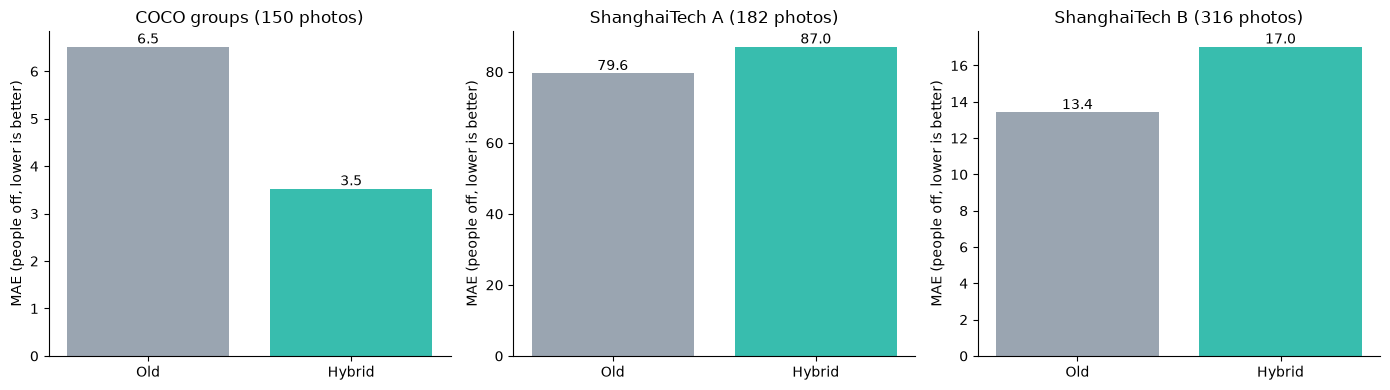

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, r in zip(axes, results.itertuples()):
    bars = ax.bar(["Old", "Hybrid"], [r._4, r._5], color=["#9AA5B1", "#38BDAE"])
    ax.bar_label(bars, fmt="%.1f")
    ax.set_title(f"{r.Set} ({r.Photos} photos)")
    ax.set_ylabel("MAE (people off, lower is better)")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 6. COCO groups by size, and which method handled each set

In [7]:
c = test[test["set"] == "COCO groups"]
rows = []
for b in ["1-5", "6-10", "11-20"]:
    d = c[c["bin"] == b]
    o, h = score(d, "old"), score(d, "hybrid")
    rows.append({"People": b, "Photos": len(d), "Old MAE": o["MAE"], "Hybrid MAE": h["MAE"], "Hybrid bias": h["Bias"],
                 "Old exact %": o["Exact %"], "Hybrid exact %": h["Exact %"],
                 "Within 1 person %": ((d["hybrid"] - d["true"]).abs() <= 1).mean() * 100})
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\nShare of photos sent to each method (%):")
print((pd.crosstab(test["set"], test["method"], normalize="index") * 100).round(1))

People  Photos  Old MAE  Hybrid MAE  Hybrid bias  Old exact %  Hybrid exact %  Within 1 person %
   1-5      50     3.10        1.28         0.80         36.0            76.0               86.0
  6-10      50     6.93        3.45         2.41         12.0            28.0               64.0
 11-20      50     9.53        5.84         3.48          6.0            14.0               34.0

Share of photos sent to each method (%):
method          dense  detector  street
set                                    
COCO groups       0.0      95.3     4.7
ShanghaiTech A   63.2       1.1    35.7
ShanghaiTech B    4.7      11.1    84.2


## 7. Where the hybrid is still wrong

In [8]:
test["abs_err"] = (test["hybrid"] - test["true"]).abs()
for name, df in test.groupby("set", sort=False):
    w = df.nlargest(3, "abs_err")
    print(name)
    for r in w.itertuples():
        print(f"   {os.path.basename(r.path):24s} true {r.true:6.0f}   hybrid {r.hybrid:7.0f}   old {r.old:7.0f}   via {r.method}")

mid = test[(test["true"] > 40) & (test["true"] <= 150)]
print(f"\nPhotos with 41-150 people in these sets: {len(mid)} (all ShanghaiTech: {(mid['set'] != 'COCO groups').all()})")
print(f"   hybrid MAE {score(mid, 'hybrid')['MAE']:.1f}, old MAE {score(mid, 'old')['MAE']:.1f}")
print("   None of these are eye-level group photos, so this test says nothing about class or wedding photos of 40-150 people.")

COCO groups
   000000560474.jpg         true      9   hybrid      89   old      89   via street
   000000373353.jpg         true     12   hybrid      85   old      85   via street
   000000274460.jpg         true     13   hybrid      63   old      63   via street
ShanghaiTech A
   IMG_8.jpg                true   1326   hybrid     892   old     892   via dense
   IMG_90.jpg               true   2256   hybrid    1841   old    1841   via dense
   IMG_165.jpg              true   1581   hybrid    1230   old    1230   via dense
ShanghaiTech B
   IMG_75.jpg               true    539   hybrid     358   old     443   via dense
   IMG_12.jpg               true    513   hybrid     337   old     448   via dense
   IMG_80.jpg               true    470   hybrid     324   old     417   via dense

Photos with 41-150 people in these sets: 207 (all ShanghaiTech: True)
   hybrid MAE 12.9, old MAE 12.0
   None of these are eye-level group photos, so this test says nothing about class or wedding photos of 

## 8. What the final test shows

| Photos | Old method (right model picked by hand) | Hybrid (picks by itself) |
|---|---|---|
| **Everyday groups, 1–13 people (COCO, 150)** | off by **6.52** | off by **3.53** (46% better) |
| **Dense crowds (ShanghaiTech A, 182)** | off by **79.6** | off by **87.0** (9% worse) |
| **Street crowds (ShanghaiTech B, 316)** | off by **13.4** | off by **17.0** (27% worse) |

- **The hybrid fixes the problem it was built for.** Exact counts on everyday groups went from 18% to 39%, and for 1–5 people from 36% to 76%.
- **It costs some crowd accuracy.** The old numbers assume the visitor always picks the right model. The hybrid has to work out the crowd type itself, and sometimes picks wrong: for example, very busy street photos go to the Dense model and get undercounted (539 counted as 358).
- **Larger groups are still weak.** With 11–13 people, only 14% of counts are exact and 34% are within one person.
- **Its worst everyday-photo errors come from routing.** When the Street model's first estimate is above 40 on a small group, the detector never runs (9 people counted as 89).
- **Not tested:** eye-level group photos of 14 or more people. The COCO subset stops at 13, and the 41–150 photos here are all ShanghaiTech crowds, so this test says nothing about a class or wedding photo of 50.

The thresholds were not changed after seeing these results.